In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Data/data0.txt', header=None, delimiter=' ')
df.drop(columns=[3], inplace=True)

df.columns = ['x1', 'x2', 'y']
df['y_str'] = df['y'].astype(str)

fig = px.scatter(df, x='x1', y='x2', color='y_str')
fig.show()

# Question 6

In [3]:
W = np.zeros((4, 2))
B = np.zeros(4)
X = df[['x1', 'x2']]

# multiclass perceptron

while True:
    df['y_pred'] = (X @ W.T + np.tile(B, (X.shape[0], 1))).idxmax(axis=1)
    if np.all(df['y'] == df['y_pred']):
        break
    else:
        for i in range(df.shape[0]):
            true = df.loc[i, 'y']
            pred = df.loc[i, 'y_pred']
            x = df.loc[i, ['x1', 'x2']]

            if true != pred:
                W[true] = W[true] + x
                B[true] = B[true] + 1
                W[pred] = W[pred] - x
                B[pred] = B[pred] - 1

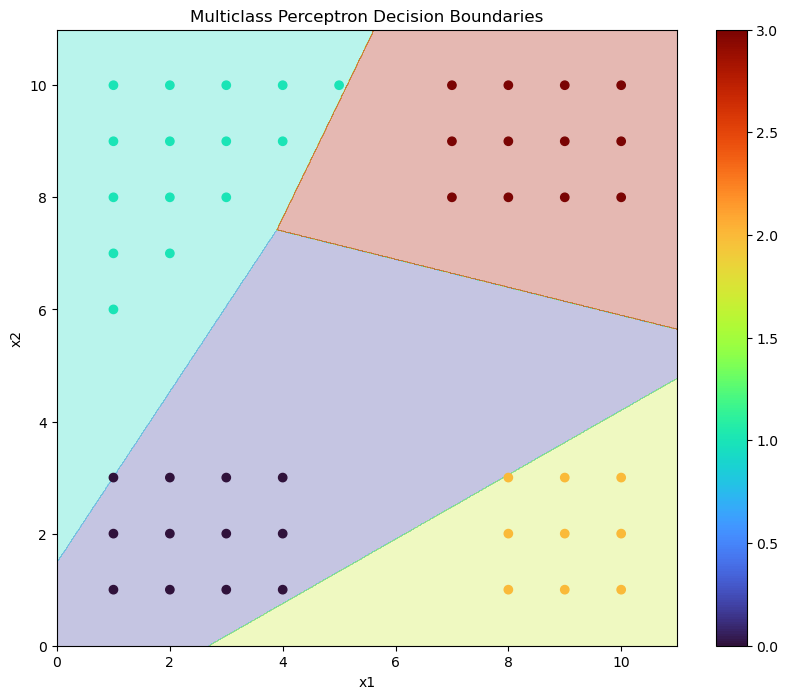

In [4]:
# Create a mesh grid for decision boundaries
x_min, x_max = df['x1'].min() - 1, df['x1'].max() + 1
y_min, y_max = df['x2'].min() - 1, df['x2'].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Predict class for each point in the mesh
Z = np.zeros((xx.shape[0], xx.shape[1]))
for i in range(xx.shape[0]):
    for j in range(xx.shape[1]):
        point = np.array([xx[i,j], yy[i,j]])
        Z[i,j] = np.argmax(W @ point + B)

# Plot decision boundaries and data points
plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='turbo')
scatter = plt.scatter(df['x1'], df['x2'], c=df['y'], cmap='turbo')
plt.colorbar(scatter)
plt.title('Multiclass Perceptron Decision Boundaries')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

# Question 7

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning:

Liblinear failed to converge, increase the number of iterations.

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning:

Liblinear failed to converge, increase the number of iterations.

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning:

Liblinear failed to converge, increase the number of iterations.

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning:

Liblinear failed to converge, increase the number of iterations.



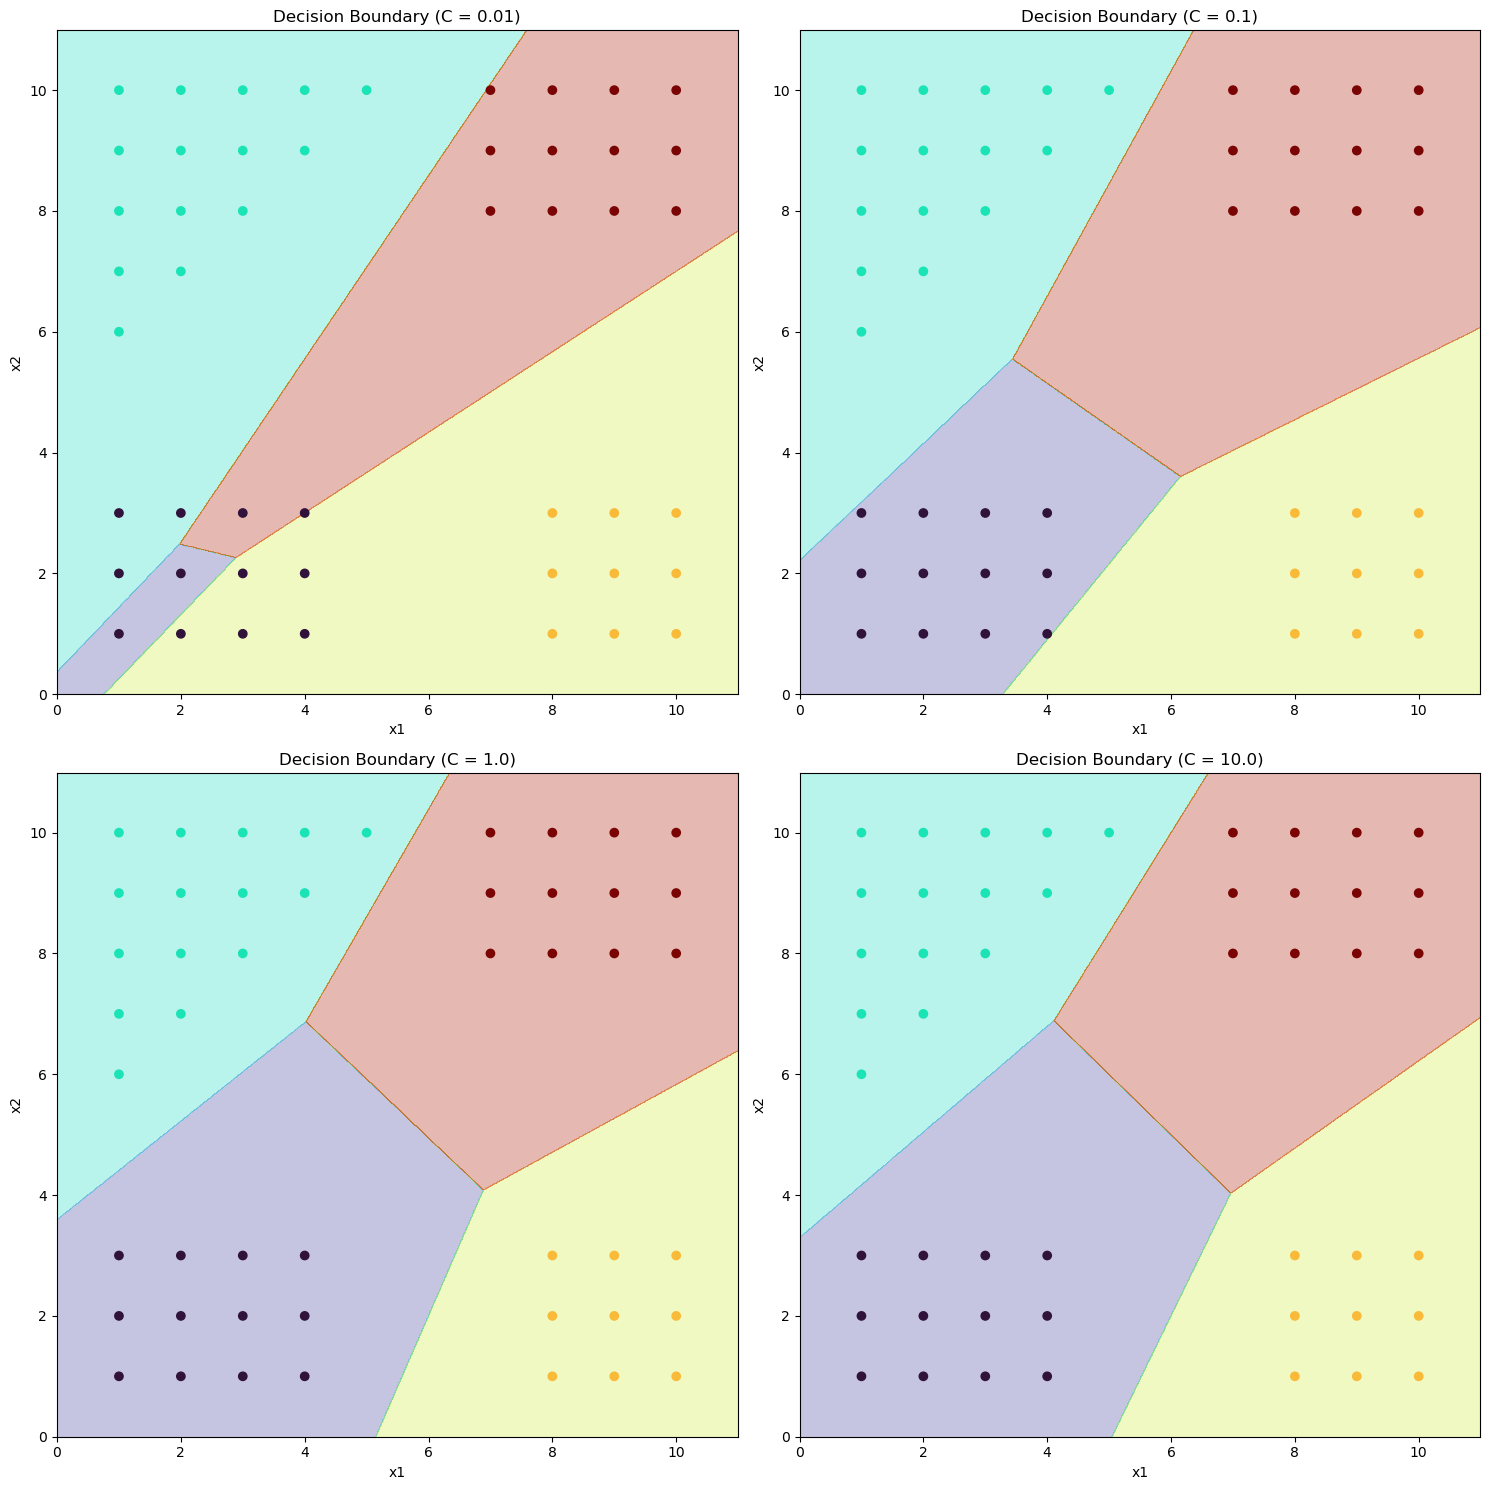


Training accuracy for different C values:
C = 0.01: 0.7917
C = 0.1: 1.0000
C = 1.0: 1.0000
C = 10.0: 1.0000


c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning:

Liblinear failed to converge, increase the number of iterations.

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning:

Liblinear failed to converge, increase the number of iterations.

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning:

Liblinear failed to converge, increase the number of iterations.

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning:

Liblinear failed to converge, increase the number of iterations.



In [5]:
from sklearn.svm import LinearSVC

X = df[['x1', 'x2']].values
y = df['y'].values

# Create a mesh grid for decision boundaries
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Values of C to try
C_values = [0.01, 0.1, 1.0, 10.0]

# Create a figure with subplots for each C value
fig, axes = plt.subplots(2, 2, figsize=(15, 15))
axes = axes.ravel()

for idx, C in enumerate(C_values):
    # Train the SVM with increased max_iter and dual=False
    svm = LinearSVC(C=C, loss='hinge', multi_class='crammer_singer', 
                    max_iter=1000000, tol=1e-4, dual=False)
    svm.fit(X, y)
    
    # Predict class for each point in the mesh
    Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Plot decision boundary
    axes[idx].contourf(xx, yy, Z, alpha=0.3, cmap='turbo')
    scatter = axes[idx].scatter(X[:, 0], X[:, 1], c=y, cmap='turbo')
    axes[idx].set_title(f'Decision Boundary (C = {C})')
    axes[idx].set_xlabel('x1')
    axes[idx].set_ylabel('x2')

plt.tight_layout()
plt.show()

# Print training accuracy for each C value
print("\nTraining accuracy for different C values:")
for C in C_values:
    svm = LinearSVC(C=C, loss='hinge', multi_class='crammer_singer', 
                    max_iter=1000000, tol=1e-4, dual=False)
    svm.fit(X, y)
    accuracy = svm.score(X, y)
    print(f"C = {C}: {accuracy:.4f}")

# Question 8

In [6]:
mini_df = pd.read_csv('Data/mini-data.txt', header=None, delimiter=' ')
mini_df.columns = ['x1', 'x2', 'y']
mini_df['y_str'] = mini_df['y'].astype(str)

fig = px.scatter(mini_df, x='x1', y='x2', color='y_str', labels={'x1': 'x1', 'x2': 'x2', 'y_str': 'y'}, title='Toy Data Set')
fig.show()

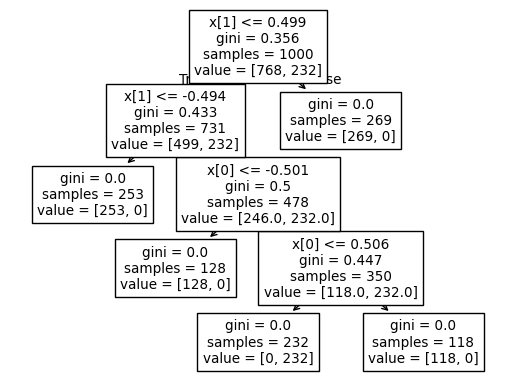

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Fit a decision tree to the data
tree = DecisionTreeClassifier(max_depth=4)
tree.fit(mini_df[['x1', 'x2']], mini_df['y'])

plot_tree(tree)
plt.show()

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning:

The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.



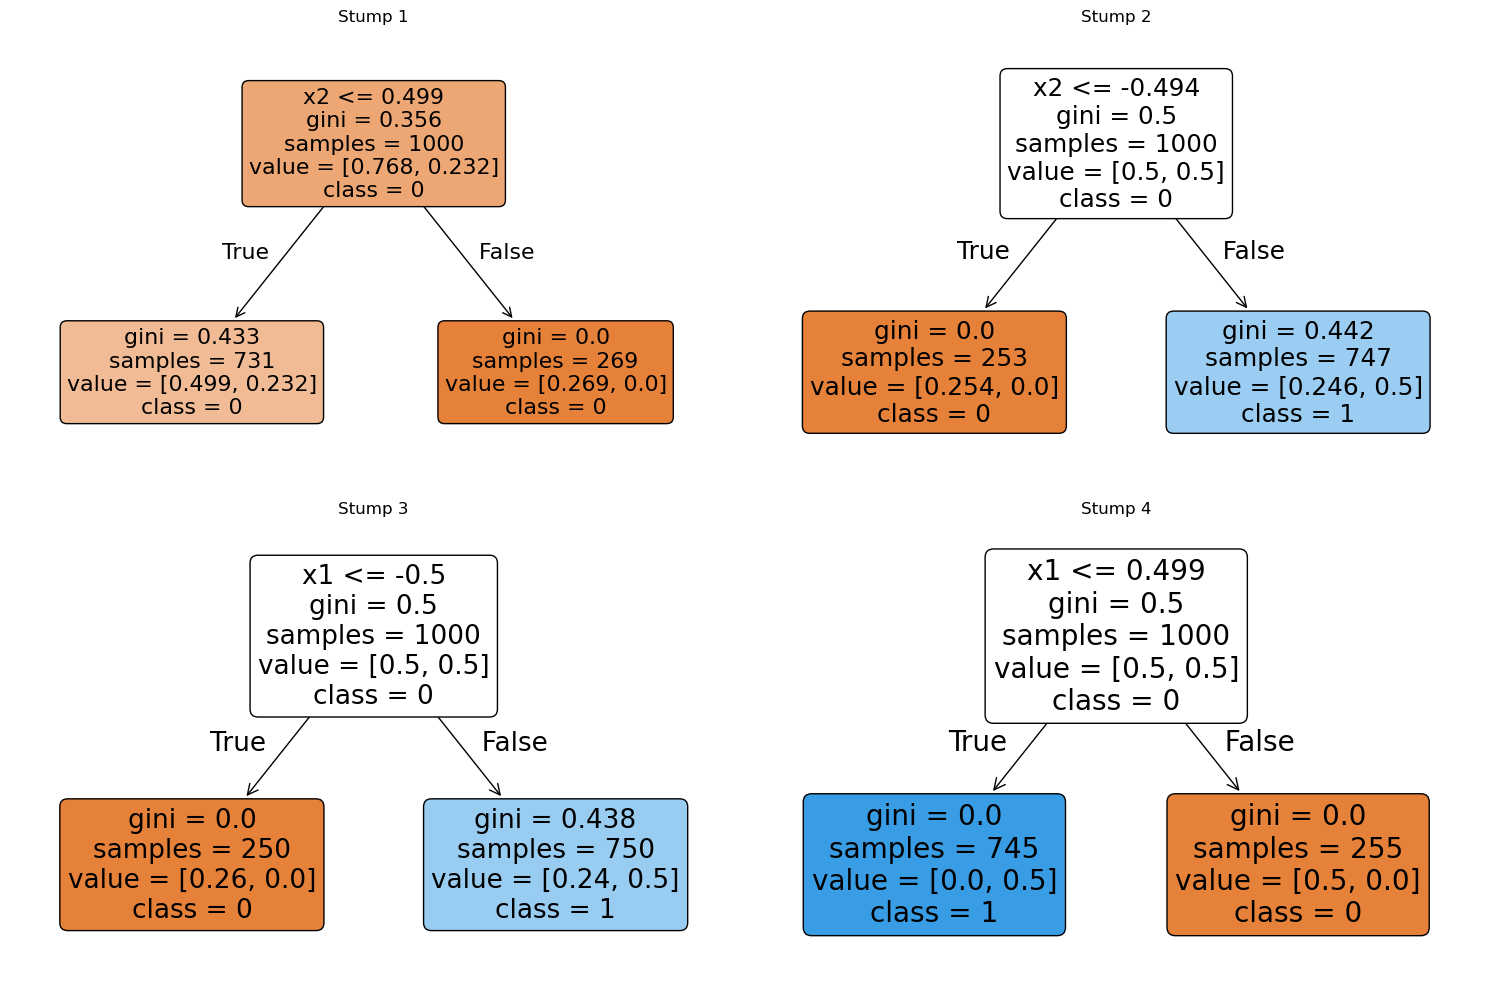


Weights of each stump:
Stump 1: 1.0000
Stump 2: 1.0000
Stump 3: 1.0000
Stump 4: 1.0000


In [15]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
import numpy as np
import matplotlib.pyplot as plt

# Create a figure with subplots for each stump
n_stumps = 4  # Using 4 stumps
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

# Fit AdaBoost with decision stumps
base_estimator = DecisionTreeClassifier(max_depth=1)  # This creates a decision stump
clf = AdaBoostClassifier(estimator=base_estimator, n_estimators=n_stumps)
clf.fit(mini_df[['x1', 'x2']], mini_df['y'])

# Plot each stump using plot_tree
for i in range(n_stumps):
    # Get the current stump
    stump = clf.estimators_[i]
    
    # Plot the decision tree
    plot_tree(stump, feature_names=['x1', 'x2'], class_names=['0', '1'], 
              filled=True, rounded=True, ax=axes[i])
    axes[i].set_title(f'Stump {i+1}')

plt.tight_layout()
plt.show()

# Print the weights of each stump
print("\nWeights of each stump:")
for i, weight in enumerate(clf.estimator_weights_):
    print(f"Stump {i+1}: {weight:.4f}")

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning:

The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\base.py:493: UserWarning:

X does not have valid feature names, but AdaBoostClassifier was fitted with feature names



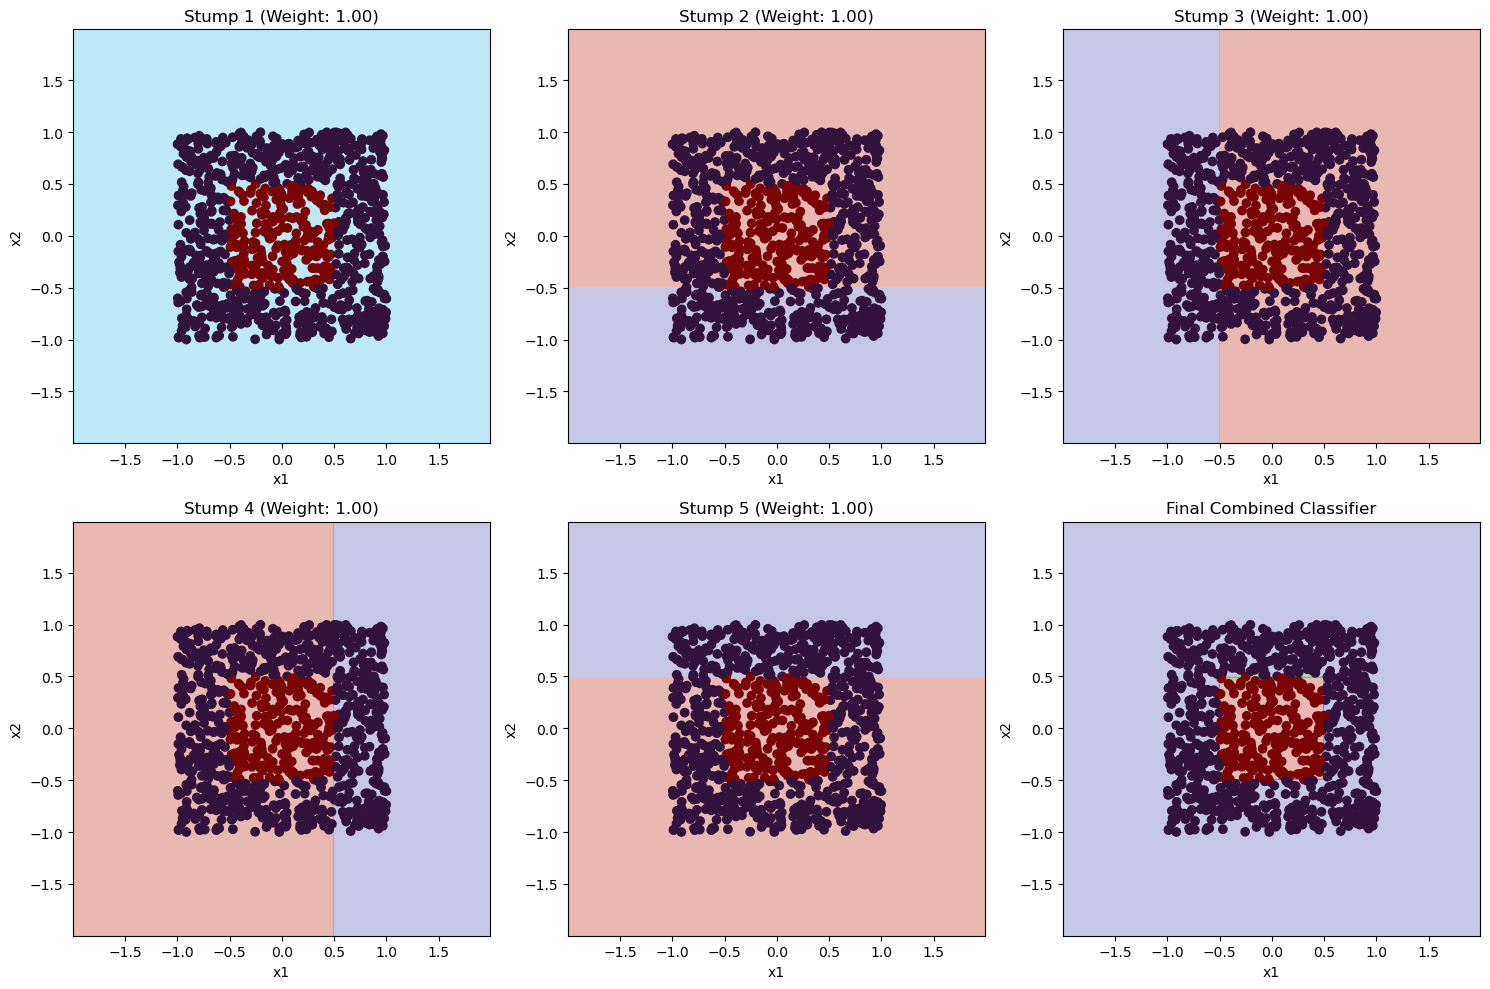


Weights of each stump:
Stump 1: 1.0000
Stump 2: 1.0000
Stump 3: 1.0000
Stump 4: 1.0000
Stump 5: 1.0000


In [9]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
import numpy as np
import matplotlib.pyplot as plt

# Create a mesh grid for decision boundaries
x_min, x_max = mini_df['x1'].min() - 1, mini_df['x1'].max() + 1
y_min, y_max = mini_df['x2'].min() - 1, mini_df['x2'].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Create a figure with subplots for each stump
n_stumps = 5  # Using 5 stumps
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

# Fit AdaBoost with decision stumps
base_estimator = DecisionTreeClassifier(max_depth=1)  # This creates a decision stump
clf = AdaBoostClassifier(estimator=base_estimator, n_estimators=n_stumps)
clf.fit(mini_df[['x1', 'x2']], mini_df['y'])

# Plot each stump's decision boundary
for i in range(n_stumps):
    # Get the current stump
    stump = clf.estimators_[i]
    
    # Get the stump's predictions
    Z = stump.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Plot decision boundary
    axes[i].contourf(xx, yy, Z, alpha=0.3, cmap='turbo')
    scatter = axes[i].scatter(mini_df['x1'], mini_df['x2'], c=mini_df['y'], cmap='turbo')
    axes[i].set_title(f'Stump {i+1} (Weight: {clf.estimator_weights_[i]:.2f})')
    axes[i].set_xlabel('x1')
    axes[i].set_ylabel('x2')

# Plot the final combined classifier
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
axes[-1].contourf(xx, yy, Z, alpha=0.3, cmap='turbo')
scatter = axes[-1].scatter(mini_df['x1'], mini_df['x2'], c=mini_df['y'], cmap='turbo')
axes[-1].set_title('Final Combined Classifier')
axes[-1].set_xlabel('x1')
axes[-1].set_ylabel('x2')

plt.tight_layout()
plt.show()

# Print the weights of each stump
print("\nWeights of each stump:")
for i, weight in enumerate(clf.estimator_weights_):
    print(f"Stump {i+1}: {weight:.4f}")

In [10]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
import numpy as np
import pandas as pd

# Create base estimator (decision stump)
base_estimator = DecisionTreeClassifier(max_depth=1)

# Create AdaBoost classifier with 10 stumps
n_stumps = 10
clf = AdaBoostClassifier(estimator=base_estimator, n_estimators=n_stumps)
clf.fit(mini_df[['x1', 'x2']], mini_df['y'])

# Track accuracy at each stage
accuracies = []
for i in range(1, n_stumps + 1):
    # Create a new classifier with i stumps
    temp_clf = AdaBoostClassifier(estimator=base_estimator, n_estimators=i)
    temp_clf.fit(mini_df[['x1', 'x2']], mini_df['y'])
    # Calculate accuracy
    accuracy = temp_clf.score(mini_df[['x1', 'x2']], mini_df['y'])
    accuracies.append(accuracy)

# Create a table of results
results = pd.DataFrame({
    'Number of Stumps': range(1, n_stumps + 1),
    'Accuracy': accuracies
})

# Display the table
print("\nAccuracy improvement with each stump:")
print(results.to_string(index=False))

# Create a plot of accuracy vs number of stumps
plt.figure(figsize=(10, 6))
plt.plot(results['Number of Stumps'], results['Accuracy'], 'bo-')
plt.xlabel('Number of Stumps')
plt.ylabel('Training Accuracy')
plt.title('Accuracy Improvement with Each Stump')
plt.grid(True)
plt.savefig('accuracy_improvement.png')
plt.close()

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning:

The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning:

The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning:

The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.

c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning:

The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.

c:\Users\issac\miniforge


Accuracy improvement with each stump:
 Number of Stumps  Accuracy
                1     0.768
                2     0.768
                3     0.882
                4     1.000
                5     1.000
                6     1.000
                7     1.000
                8     1.000
                9     1.000
               10     1.000
